In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *



%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


# Figure 3: Data set types

### Helper functions

In [2]:
def set_size(w,h, ax=None):
    """ w, h: width, height in inches """
    if not ax: ax=plt.gca()
    l = ax.figure.subplotpars.left
    r = ax.figure.subplotpars.right
    t = ax.figure.subplotpars.top
    b = ax.figure.subplotpars.bottom
    figw = float(w)/(r-l)
    figh = float(h)/(t-b)
    ax.figure.set_size_inches(figw, figh)

In [3]:
def sort_by_mean_time(cells):
    times = [ np.median(cell.time) for cell in cells ]
    return np.array(cells)[np.argsort(times)]


In [4]:

def bin_with_error_bars(means, variances, n_bins=1000, return_edges=True, ignore_errors=False):
    if ignore_errors:
        return np.histogram(means, bins="auto")
    left = np.min(means) - 2*np.sqrt(variances[np.argmin(means)])
    right = np.max(means) + 2*np.sqrt(variances[np.argmax(means)])
    
    _,bin_edges = np.histogram(means, bins=np.linspace(left, right, n_bins))
    
    bin_c = bin_edges[:-1] +np.diff(bin_edges)/2
    weight = np.zeros_like(bin_c)
    for i, m in enumerate(means):
        weight += special.erf( (bin_edges[1:]-m)/np.sqrt(2*variances[i]) ) - special.erf( (bin_edges[:-1]-m)/np.sqrt(2*variances[i]) )
    if return_edges:
        return weight, bin_edges
    else:
        return weight, bin_c


    
color=["tab:blue", "tab:orange", "tab:green", "tab:olive"]*100


### Switching conditions

### Stable conditions

In [22]:

filename = "../../data_realtrace_paper/ecoli_data/glucose020_hi1_20190515_rawdata_f01234578910_b_prediction.csv"
data = pd.read_csv(filename, skiprows=header_lines(filename))
vanilla_cells_data = df2ggp_cells(data)

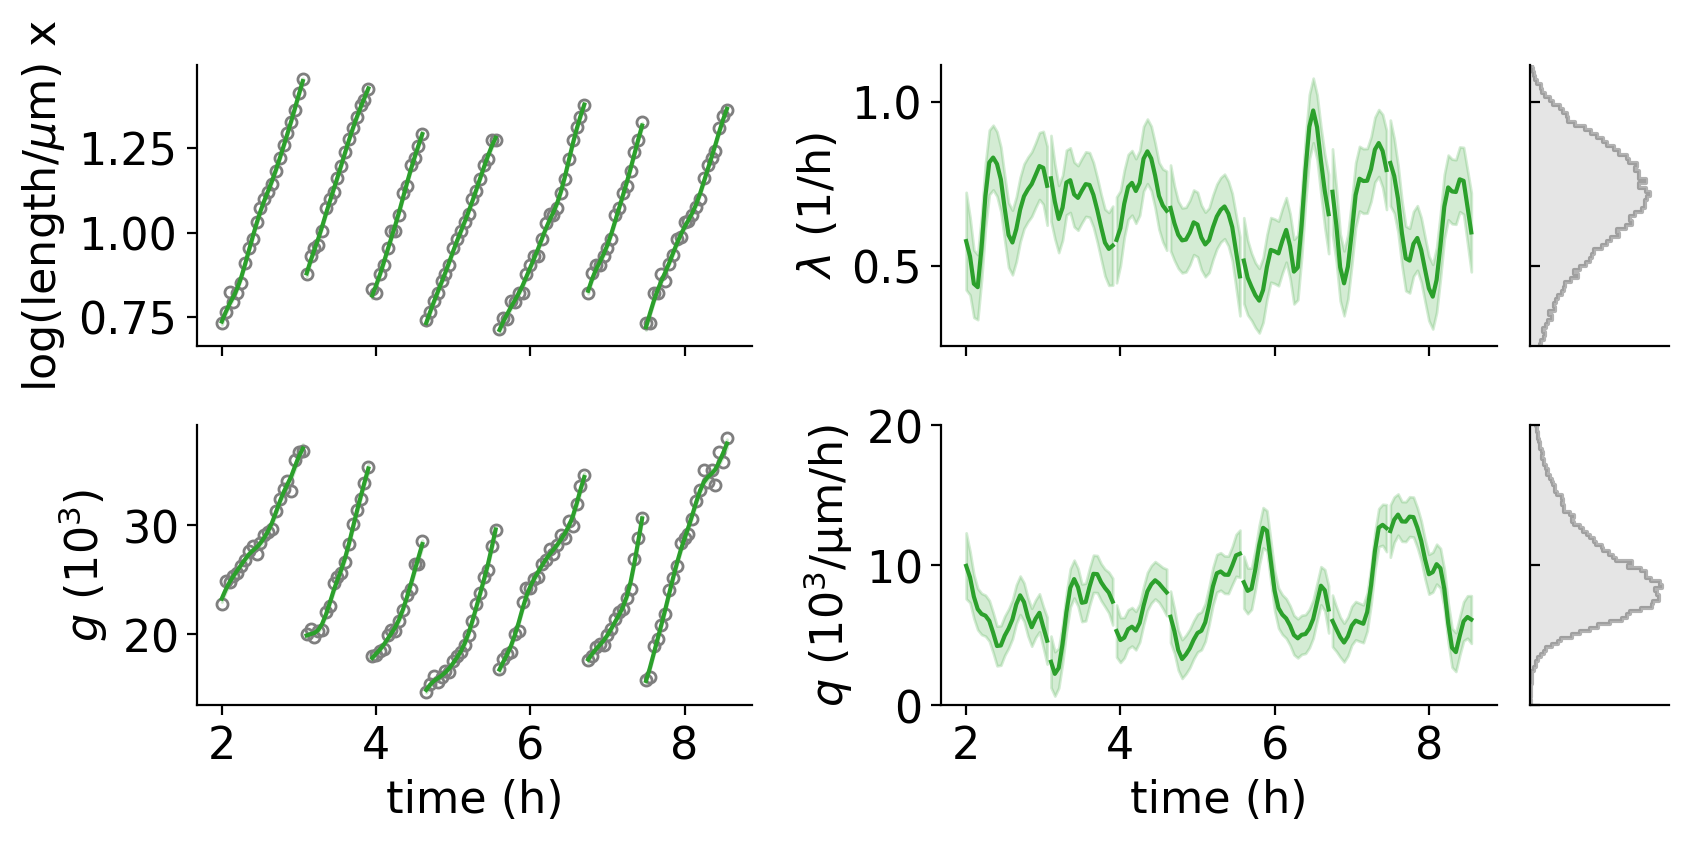

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>],
      dtype=object)

In [24]:
def plot_predictions_vanilla_cells(cells, cell_idx, time_unit=("h", 60), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
        
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE*0.7,FULL_HEIGHT), sharex=True)
    # fig, axes = plt.subplots(1,4, figsize=(16,4), sharex=True)

    axes = axes.transpose()
    ax = axes.ravel()

    s = 10
    lw = 1.5
    
    time = np.concatenate([cell.time for cell in cells])
    
    ### LAMBDA
    l_coll = np.concatenate([cell.mean_l for cell in cells])
    l_var_coll = np.concatenate([cell.cov_ll for cell in cells])
    
    ### Q
    q_coll = np.concatenate([cell.mean_q for cell in cells])/1e3
    q_var_coll = np.concatenate([cell.cov_qq for cell in cells])/1e6
    
    n_lines = (len(cell_idx)-1)*2
    
    for i, cell in enumerate(cells):
        if i not in cell_idx:
            continue
        time = np.array(cell.time) / time_unit[1]
        prediction_color = color[0]
        rate_color = color[0]
        color = color[1:]

        ax[0].plot(time, cell.log_length, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[0].plot(time, cell.mean_x, color=prediction_color, lw=lw)
        ax[0].fill_between(time, cell.mean_x-np.sqrt(cell.cov_xx), cell.mean_x+np.sqrt(cell.cov_xx), 
                    color=prediction_color, alpha=0.2)
        
        
        ax[1].plot(time, cell.gfp/1e3, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[1].plot(time, cell.mean_g/1e3, color=prediction_color, lw=lw)
        ax[1].fill_between(time, 
                           (cell.mean_g-np.sqrt(cell.cov_gg))/1e3,
                           (cell.mean_g+np.sqrt(cell.cov_gg))/1e3, 
                    color=prediction_color, alpha=0.2)
        
        ax[2].plot(time, cell.mean_l*60, color=rate_color, lw=lw)
        ax[2].fill_between(time, (cell.mean_l-np.sqrt(cell.cov_ll))*60, (cell.mean_l+np.sqrt(cell.cov_ll))*60, 
                    color=rate_color, alpha=0.2)

        ax[3].plot(time, cell.mean_q*60/1e3, color=rate_color, lw=lw)
        ax[3].fill_between(time, 
                           (cell.mean_q-np.sqrt(cell.cov_qq))*60/1e3, 
                           (cell.mean_q+np.sqrt(cell.cov_qq))*60/1e3, 
                    color=rate_color, alpha=0.2)
        
        

        # for a in ax[-2:]:
        #     if n_lines>0:
        #         a.axvline(time[-1]+(time[-1]-time[-2])/2.,color="tab:grey", lw=0.5,)
        #     n_lines-=1
            
    for i in range(4):
        ax[i].set_xlim(xlim)
        
    if mark_transition:
        for a in ax:
            a_ylim = a.get_ylim()
            a_xlim = a.get_xlim()
            a.add_patch(plt.Rectangle((12, a_ylim[0]), a_xlim[1]-12, a_ylim[1], 
                                      transform=a.transData, 
                                      color='lightgrey', 
                                      alpha=0.3))
        
    # ax[0].set_ylabel("log length $x$ ($\mu$m) ")   
    # ax[1].set_ylabel("GFP content $g$ (a.u.)")   
    # ax[2].set_ylabel(r"growth rate $\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"prod. rate $q$ $\mathrm{(a.u./\mu m/h)}$")   
    
    # ax[0].set_ylabel("$x$ ($\mu$m)")   
    # ax[1].set_ylabel("$g$ (a.u.)")   
    # ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"$q$ $\mathrm{(a.u./\mu m/h)}$")   

    ax[0].set_ylabel("log(length/$\mu$m) x")  
    ax[1].set_ylabel("$g$ ($10^3$)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(10^3/\mu m/h)}$")   

    # ax[0].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    # ax[2].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)

    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()
       
    #################### HIST
    ax_histy = ax[2].inset_axes([1.06, 0, 0.25, 1], sharey=ax[2])
    ax_histy.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll)*60, np.ravel(l_var_coll)*60**2,
                                          ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy.set_xticks([])
    
    #################### HIST
    ax_histy2 = ax[3].inset_axes([1.06, 0, 0.25, 1], sharey=ax[3], sharex=ax_histy)
    ax_histy2.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy2.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll)*60, np.ravel(q_var_coll)*60**2, 
                                          ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy2.set_xticks([])

        
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(0, 20)
    fig.tight_layout()
    
    for a in list(ax) + [ax_histy,ax_histy2]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        set_size(FULL_SIZE*0.5,FULL_HEIGHT*0.8, a)
        
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax



plot_predictions_vanilla_cells(vanilla_cells_data, 
                     get_longest_path(vanilla_cells_data)[:7], 
                     outfile="../../figures_for_method_paper/plots_main/traces/vanilla.pdf",
                    color=["tab:green"]*10,
                    ignore_errors=True)



### C elegans

In [14]:
filename_worm = "../../data_realtrace_paper/celegans_data/formatted_f01234578_b_prediction.csv"
worm_data = df2ggp_cells(pd.read_csv(filename_worm, skiprows=header_lines(filename_worm)))

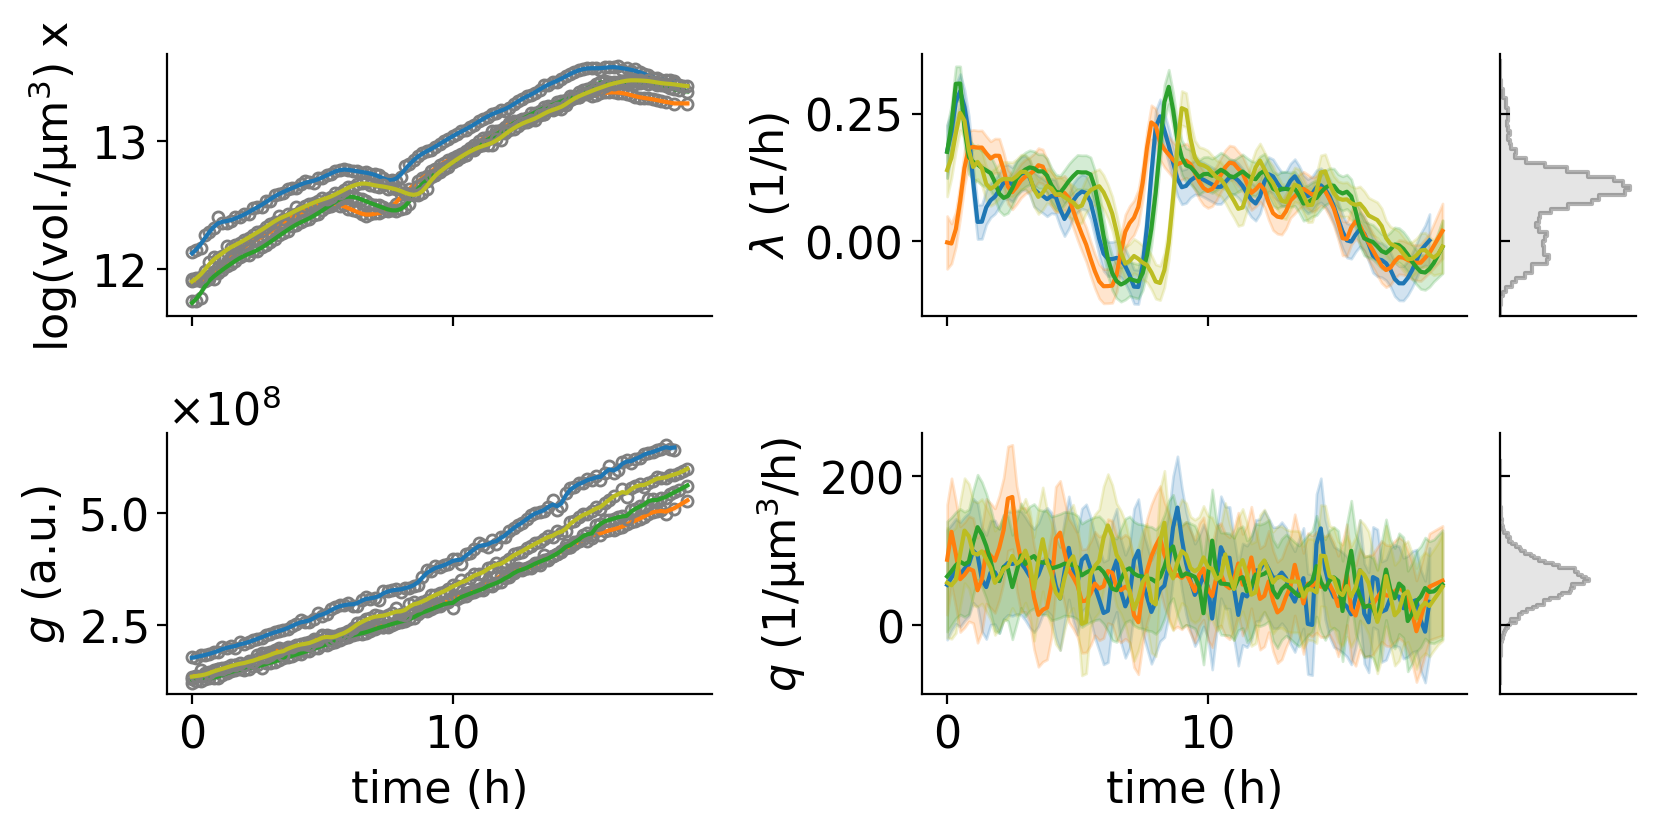

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>],
      dtype=object)

In [15]:
def plot_predictions_worms(cells, cell_idx, time_unit=("h", 60), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100, 
                          ignore_errors=False):
                           
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE*0.7,FULL_HEIGHT), sharex=True)
    # fig, axes = plt.subplots(1,4, figsize=(16,4))

    axes = axes.transpose()
    ax = axes.ravel()

#     norm = mpl.colors.Normalize(vmin=-len(cells_data)/2, vmax=len(cells_data))
#     if len(cells_data)==1:
#         norm = mpl.colors.Normalize(vmin=-10*len(cells_data), vmax=len(cells_data))

#     cmap_data = mpl.cm.ScalarMappable(cmap='Oranges', norm=norm)
#     cmap_data.set_array([])

#     cmap_prediction = mpl.cm.ScalarMappable(cmap='Blues', norm=norm)
#     cmap_prediction.set_array([])


    s = 10
    lw = 1.5
    
    time = np.concatenate([cell.time for cell in cells])
    
    ### LAMBDA
    l_coll = np.concatenate([cell.mean_l for cell in cells])
    l_var_coll = np.concatenate([cell.cov_ll for cell in cells])
    
    ### Q
    q_coll = np.concatenate([cell.mean_q for cell in cells])
    q_var_coll = np.concatenate([cell.cov_qq for cell in cells])
    
    for i, cell in enumerate(cells):
        if i not in cell_idx:
            continue
        time = np.array(cell.time) / time_unit[1]
        prediction_color = color[0]
        rate_color = color[0]
        color = color[1:]

        ax[0].plot(time, cell.log_length, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[0].plot(time, cell.mean_x, color=prediction_color, lw=lw)
        ax[0].fill_between(time, cell.mean_x-np.sqrt(cell.cov_xx), cell.mean_x+np.sqrt(cell.cov_xx), 
                    color=prediction_color, alpha=0.2)
        
        
        ax[1].plot(time, cell.gfp, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[1].plot(time, cell.mean_g, color=prediction_color, lw=lw)
        ax[1].fill_between(time, cell.mean_g-np.sqrt(cell.cov_gg), cell.mean_g+np.sqrt(cell.cov_gg), 
                    color=prediction_color, alpha=0.2)
        
        ax[2].plot(time, cell.mean_l*60, color=rate_color, lw=lw)
        ax[2].fill_between(time, (cell.mean_l-np.sqrt(cell.cov_ll))*60, (cell.mean_l+np.sqrt(cell.cov_ll))*60, 
                    color=rate_color, alpha=0.2)

        ax[3].plot(time, cell.mean_q*60, color=rate_color, lw=lw)
        ax[3].fill_between(time, (cell.mean_q-np.sqrt(cell.cov_qq))*60, (cell.mean_q+np.sqrt(cell.cov_qq))*60, 
                    color=rate_color, alpha=0.2)

    for i in range(4):
        ax[i].set_xlim(xlim)
        
    if mark_transition:
        for a in ax:
            a_ylim = a.get_ylim()
            a_xlim = a.get_xlim()
            a.add_patch(plt.Rectangle((12, a_ylim[0]), a_xlim[1]-12, a_ylim[1], 
                                      transform=a.transData, 
                                      color='lightgrey', 
                                      alpha=0.3))
        
    # ax[0].set_ylabel("log volume $x$ $\mathrm{(\mu m^3)}$ ")   
    # ax[1].set_ylabel("GFP content $g$ (a.u.)")   
    # ax[2].set_ylabel(r"growth rate $\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"prod. rate $q$ $\mathrm{(a.u./\mu m/h)}$")   

    # ax[0].set_ylabel("$x$ $\mathrm{(\mu m^3)}$ ")   
    # ax[1].set_ylabel("$g$ (a.u.)")   
    # ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"$q$ $\mathrm{(a.u./\mu m^3/h)}$")   


    ax[0].set_ylabel("log(vol./$\mathrm{\mu m^3}$) x")   
    ax[1].set_ylabel("$g$ (a.u.)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(1/\mu  m^3/h)}$")   


    # ax[0].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    # ax[2].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-3,3], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-3,3], useMathText=True)

    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()
       
    #################### HIST
    ax_histy = ax[2].inset_axes([1.06, 0, 0.25, 1], sharey=ax[2])
    ax_histy.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll)*60, np.ravel(l_var_coll)*60**2, ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy.set_xticks([])

    #################### HIST
    ax_histy2 = ax[3].inset_axes([1.06, 0, 0.25, 1], sharey=ax[3], sharex=ax_histy)
    ax_histy2.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy2.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll)*60, np.ravel(q_var_coll)*60**2, ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy2.set_xticks([])

        
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(ax3_lim)
    fig.tight_layout()
    
    for a in list(ax) + [ax_histy,ax_histy2]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        set_size(FULL_SIZE*0.5,FULL_HEIGHT*0.8, a)
        
    

    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax

plot_predictions_worms(sort_by_mean_time(worm_data), 
                       np.arange(1, 5, 1), 
                       outfile="../../figures_for_method_paper/plots_main/traces/worms.pdf",
                       color=["tab:blue", "tab:orange", "tab:green", "tab:olive"]*100, 
                       ignore_errors=True)


### Stem cells

In [17]:
filename_esc = "../../data_realtrace_paper/esc_data/MCFT-Raly_B_mod1_f01234578910_b_prediction.csv"
data_esc = pd.read_csv(filename_esc, skiprows=header_lines(filename_esc))
esc_data = df2ggp_cells(data_esc)

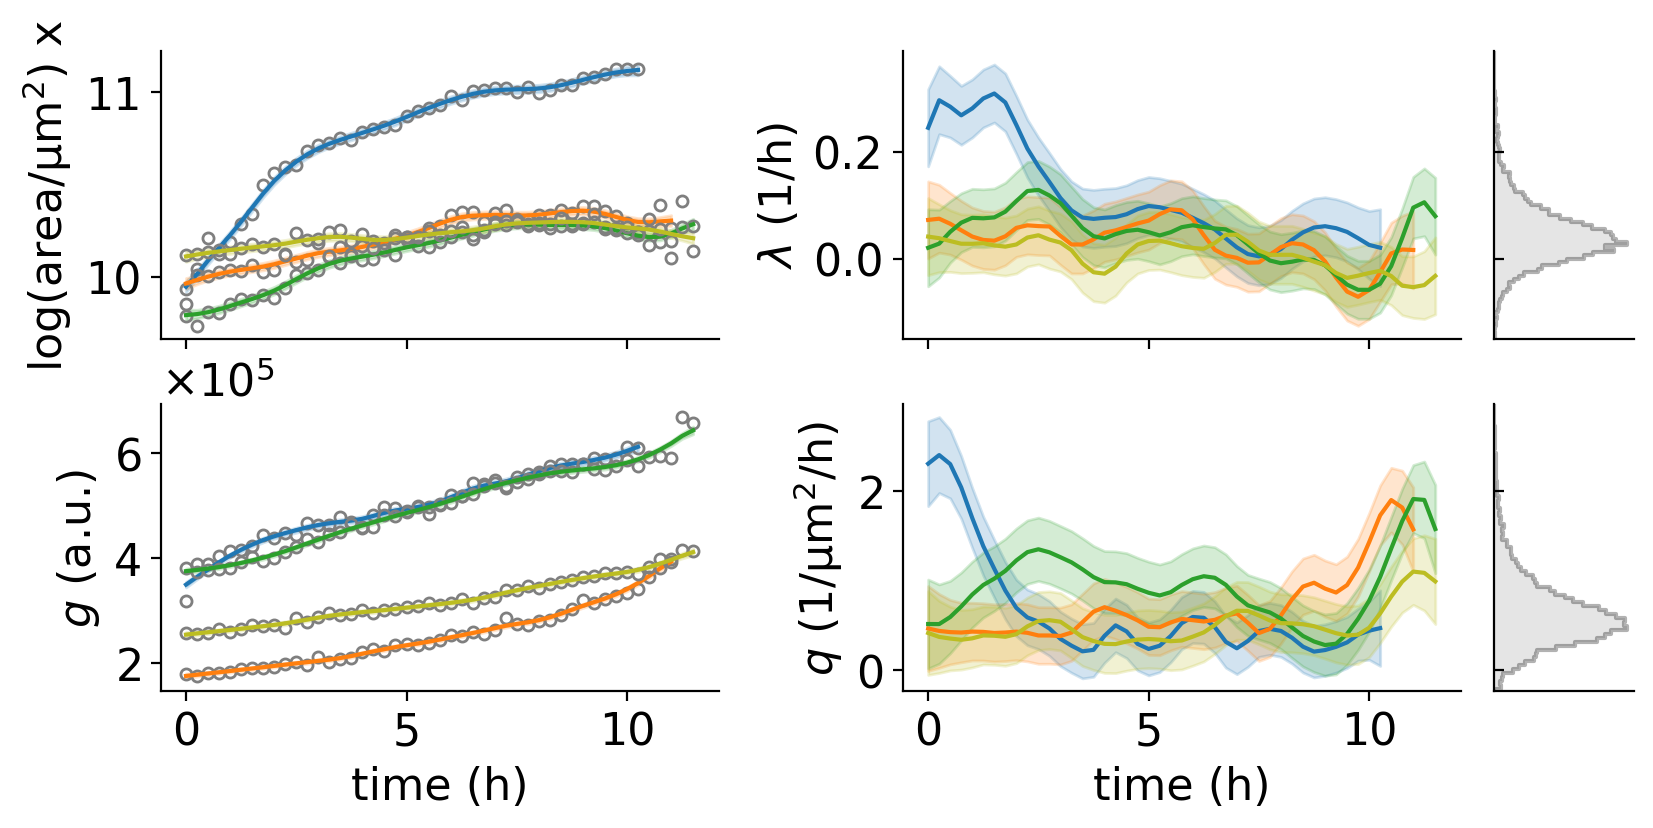

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>],
      dtype=object)

In [18]:
def plot_predictions_ecs(cells, cell_idx, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE*0.7,FULL_HEIGHT), sharex=True)

    axes = axes.transpose()
    ax = axes.ravel()

    s = 10
    lw = 1.5
    
    time = np.concatenate([cell.time for cell in cells])
    
    ### LAMBDA
    l_coll = np.concatenate([cell.mean_l for cell in cells])
    l_var_coll = np.concatenate([cell.cov_ll for cell in cells])
    
    ### Q
    q_coll = np.concatenate([cell.mean_q for cell in cells])
    q_var_coll = np.concatenate([cell.cov_qq for cell in cells])
    
    for i, cell in enumerate(cells):
        if i not in cell_idx:
            continue
        time = np.array(cell.time) / time_unit[1]
        prediction_color = color[0]
        rate_color = color[0]
        color = color[1:]

        ax[0].plot(time, cell.log_length, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[0].plot(time, cell.mean_x, color=prediction_color, lw=lw)
        ax[0].fill_between(time, cell.mean_x-np.sqrt(cell.cov_xx), cell.mean_x+np.sqrt(cell.cov_xx), 
                    color=prediction_color, alpha=0.2)
        
        
        ax[1].plot(time, cell.gfp, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[1].plot(time, cell.mean_g, color=prediction_color, lw=lw)
        ax[1].fill_between(time, cell.mean_g-np.sqrt(cell.cov_gg), cell.mean_g+np.sqrt(cell.cov_gg), 
                    color=prediction_color, alpha=0.2)
        
        ax[2].plot(time, cell.mean_l, color=rate_color, lw=lw)
        ax[2].fill_between(time, cell.mean_l-np.sqrt(cell.cov_ll), cell.mean_l+np.sqrt(cell.cov_ll), 
                    color=rate_color, alpha=0.2)

        ax[3].plot(time, cell.mean_q, color=rate_color, lw=lw)
        ax[3].fill_between(time, cell.mean_q-np.sqrt(cell.cov_qq), cell.mean_q+np.sqrt(cell.cov_qq), 
                    color=rate_color, alpha=0.2)

    for i in range(4):
        ax[i].set_xlim(xlim)
        
    if mark_transition:
        for a in ax:
            a_ylim = a.get_ylim()
            a_xlim = a.get_xlim()
            a.add_patch(plt.Rectangle((12, a_ylim[0]), a_xlim[1]-12, a_ylim[1], 
                                      transform=a.transData, 
                                      color='lightgrey', 
                                      alpha=0.3))
                

    ax[0].set_ylabel("log(area/$\mathrm{\mu m^2}$) x")   
    ax[1].set_ylabel("$g$ (a.u.)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(1/\mu  m^2/h)}$")   

    # ax[0].set_ylabel("$x$ $\mathrm{(\mu m^2)}$ ")   
    # ax[1].set_ylabel("$g$ (a.u.)")   
    # ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"$q$ $\mathrm{(a.u./\mu m^2/h)}$")   



    # ax[0].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    # ax[2].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)

    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()
       
    #################### HIST
    ax_histy = ax[2].inset_axes([1.06, 0, 0.25, 1], sharey=ax[2])
    ax_histy.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll), np.ravel(l_var_coll),ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy.set_xticks([])
  
    #################### HIST
    ax_histy2 = ax[3].inset_axes([1.06, 0, 0.25, 1], sharey=ax[3], sharex=ax_histy)
    ax_histy2.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy2.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll), np.ravel(q_var_coll), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy2.set_xticks([])

        
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(ax3_lim)
    
    fig.tight_layout(h_pad=0)

    for a in list(ax) + [ax_histy,ax_histy2]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()    
        set_size(FULL_SIZE*0.5,FULL_HEIGHT*0.8, a)
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_predictions_ecs(sort_by_mean_time(esc_data), 
                     np.arange(10, 14, 1), 
                     outfile="../../figures_for_method_paper/plots_main/traces/ESCs.pdf",
                    color=color,
                    ignore_errors=True)
